## **Detecting Fraudulent Financial Transactions - DA4641 - Introduction to FinTech - Group 8**

Install/Import libraries

In [28]:
# Install extra libraries not pre-installed on Colab
!pip install -q imbalanced-learn xgboost

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                              average_precision_score, precision_recall_curve, roc_curve,
                              ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
np.random.seed(42)

Upload the file

In [29]:
from google.colab import files

uploaded = files.upload()  # select dataset02.csv from your computer
filename = list(uploaded.keys())[0]
print(f"Uploaded: {filename}")

Saving dataset02.csv to dataset02 (1).csv
Uploaded: dataset02 (1).csv


Load and do initial inspection

In [30]:
df = pd.read_csv(filename)

print("Shape:", df.shape)
df.head()

Shape: (5191, 20)


,transaction_id,customer_id,transaction_datetime,transaction_amount,merchant_category,transaction_type,card_type,card_present,account_age_days,customer_age,customer_country,merchant_country,distance_from_home_km,transaction_hour,num_transactions_last_24h,avg_transaction_amount_last_30d,device_type,ip_risk_score,previous_fraud_flag,is_fraud
0,TXN504612,CU20606,03/12/2024 02:20,6.26,Healthcare,POS,Debit,No,1394,81.0,Germany,Nigeria,35.83,9,2,30.69,NaN,0.373,No,0
1,TXN502089,CU70518,2024-12-08 00:22:00,49.72,Fuel,POS,Debit,Yes,551,40.0,Canada,USA,28.28,23,1,382.35,Mobile,0.089,No,0
2,TXN502323,CU17242,06-28-2024 03:58:00,24.74,Grocery,Online,CREDIT,Yes,325,71.0,India,India,42.42,4,4,33.20,Desktop,0.058,No,0
3,TXN503403,CU35677,2024-08-17 12:27:00,251.90,TRAVEL,Mobile Payment,debit,no,1488,65.0,UAE,Germany,6.42,11,2,41.62,ATM,0.396,No,0
4,TXN503745,CU12838,12/08/2024 05:02,177.97,Restaurant,Mobile Payment,Debit,YES,465,80.0,UK,Sri Lanka,73.59,5,1,233.98,Mobile,0.175,No,0


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5191 entries, 0 to 5190
Data columns (total 20 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   transaction_id                   5191 non-null   object 
 1   customer_id                      5191 non-null   object 
 2   transaction_datetime             5191 non-null   object 
 3   transaction_amount               4996 non-null   float64
 4   merchant_category                4964 non-null   object 
 5   transaction_type                 5191 non-null   object 
 6   card_type                        5191 non-null   object 
 7   card_present                     4995 non-null   object 
 8   account_age_days                 5191 non-null   int64  
 9   customer_age                     4979 non-null   float64
 10  customer_country                 5191 non-null   object 
 11  merchant_country                 5191 non-null   object 
 12  distance_from_home_k

In [32]:
print("Missing values per column:\n")
print(df.isna().sum())

Missing values per column:

transaction_id                       0
customer_id                          0
transaction_datetime                 0
transaction_amount                 195
merchant_category                  227
transaction_type                     0
card_type                            0
card_present                       196
account_age_days                     0
customer_age                       212
customer_country                     0
merchant_country                     0
distance_from_home_km              445
transaction_hour                     0
num_transactions_last_24h            0
avg_transaction_amount_last_30d    179
device_type                        413
ip_risk_score                      341
previous_fraud_flag                  0
is_fraud                             0
dtype: int64


Data cleaning: duplicates

In [33]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated transaction_id:", df['transaction_id'].duplicated().sum())

df = df.drop_duplicates(subset='transaction_id', keep='first').reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Fully duplicated rows: 91
Duplicated transaction_id: 91
Shape after removing duplicates: (5100, 20)


Data cleaning: standardize messy categorical text

In [34]:
# Many categorical columns have inconsistent casing, whitespace, and
# underscore/space variants (e.g. 'Grocery', ' GROCERY ', 'grocery')

categorical_cols = ['merchant_category', 'transaction_type', 'card_type',
                     'card_present', 'customer_country', 'merchant_country',
                     'device_type', 'previous_fraud_flag']

def clean_categorical(series):
    return (series.astype(str)
                  .str.strip()
                  .str.replace('_', ' ', regex=False)
                  .str.lower()
                  .str.title()
                  .replace('Nan', np.nan))

for col in categorical_cols:
    df[col] = clean_categorical(df[col])

# Standardize Yes/No fields specifically
for col in ['card_present', 'previous_fraud_flag']:
    df[col] = df[col].map({'Yes': 'Yes', 'No': 'No'})

for col in categorical_cols:
    print(col, '->', sorted(df[col].dropna().unique()))
    print()

merchant_category -> ['Electronics', 'Entertainment', 'Fuel', 'Grocery', 'Healthcare', 'Jewelry', 'Online Retail', 'Other', 'Restaurant', 'Travel', 'Utilities']

transaction_type -> ['Atm Withdrawal', 'Mobile Payment', 'Online', 'Pos', 'Wire Transfer']

card_type -> ['Credit', 'Debit', 'Prepaid']

card_present -> ['No', 'Yes']

customer_country -> ['Australia', 'Brazil', 'Canada', 'Germany', 'India', 'Nigeria', 'Singapore', 'Sri Lanka', 'Uae', 'Uk', 'Usa']

merchant_country -> ['Australia', 'Brazil', 'Canada', 'Germany', 'India', 'Nigeria', 'Singapore', 'Sri Lanka', 'Uae', 'Uk', 'Usa']

device_type -> ['Atm', 'Desktop', 'Mobile', 'Pos Terminal', 'Unknown']

previous_fraud_flag -> ['No', 'Yes']



Data cleaning: parse mixed-format datetimes

In [35]:
# transaction_datetime arrives in several formats: DD/MM/YYYY HH:MM,
# MM-DD-YYYY HH:MM:SS, YYYY-MM-DD HH:MM:SS, etc.
# We try a list of known formats and fall back to pandas' flexible parser.

known_formats = [
    '%d/%m/%Y %H:%M',
    '%m-%d-%Y %H:%M:%S',
    '%Y-%m-%d %H:%M:%S',
    '%m/%d/%Y %H:%M',
    '%d-%m-%Y %H:%M:%S',
]

def parse_mixed_datetime(value):
    if pd.isna(value):
        return pd.NaT
    for fmt in known_formats:
        try:
            return datetime.strptime(str(value).strip(), fmt)
        except ValueError:
            continue
    return pd.to_datetime(value, errors='coerce', dayfirst=False)

df['transaction_datetime'] = df['transaction_datetime'].apply(parse_mixed_datetime)
print("Unparsed datetimes:", df['transaction_datetime'].isna().sum())

# Derive calendar features
df['txn_month'] = df['transaction_datetime'].dt.month
df['txn_dayofweek'] = df['transaction_datetime'].dt.dayofweek

Unparsed datetimes: 0


Data cleaning: invalid values

In [36]:
# customer_age has implausible values (0 and 150 seen in the raw data)
print(df['customer_age'].describe())

# Treat ages outside a plausible adult range as invalid -> set to NaN, impute later
df.loc[(df['customer_age'] < 18) | (df['customer_age'] > 100), 'customer_age'] = np.nan

# transaction_amount: check for negatives / zeros (shouldn't be negative)
print("Negative amounts:", (df['transaction_amount'] < 0).sum())
df.loc[df['transaction_amount'] < 0, 'transaction_amount'] = np.nan

# ip_risk_score should be within [0, 1] by definition
print("ip_risk_score out of range:", ((df['ip_risk_score'] < 0) | (df['ip_risk_score'] > 1)).sum())

count    4895.000000
mean       51.071502
std        19.409093
min         0.000000
25%        35.000000
50%        51.000000
75%        68.000000
max       150.000000
Name: customer_age, dtype: float64
Negative amounts: 0
ip_risk_score out of range: 0


# **Exploratory Data Analysis (EDA)**



Class balance (is_fraud):
is_fraud
0    4620
1     480
Name: count, dtype: int64
is_fraud
0    90.588235
1     9.411765
Name: proportion, dtype: float64


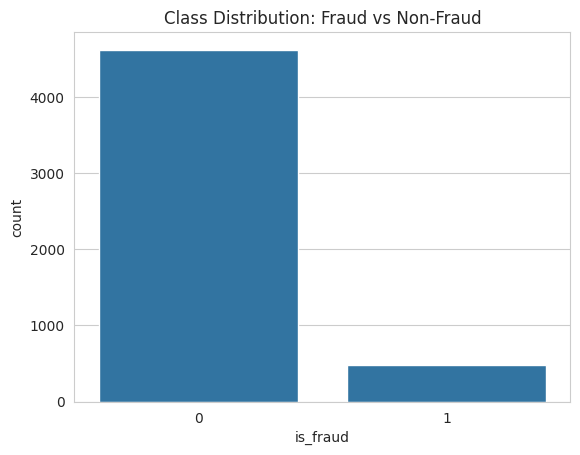

In [37]:
print("Class balance (is_fraud):")
print(df['is_fraud'].value_counts())
print(df['is_fraud'].value_counts(normalize=True) * 100)

sns.countplot(x='is_fraud', data=df)
plt.title('Class Distribution: Fraud vs Non-Fraud')
plt.show()

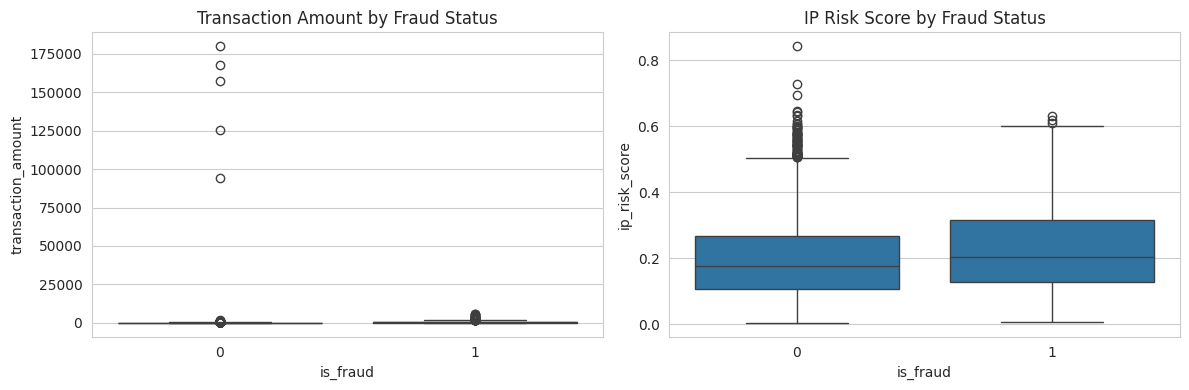

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x='is_fraud', y='transaction_amount', data=df, ax=axes[0])
axes[0].set_title('Transaction Amount by Fraud Status')
sns.boxplot(x='is_fraud', y='ip_risk_score', data=df, ax=axes[1])
axes[1].set_title('IP Risk Score by Fraud Status')
plt.tight_layout()
plt.show()

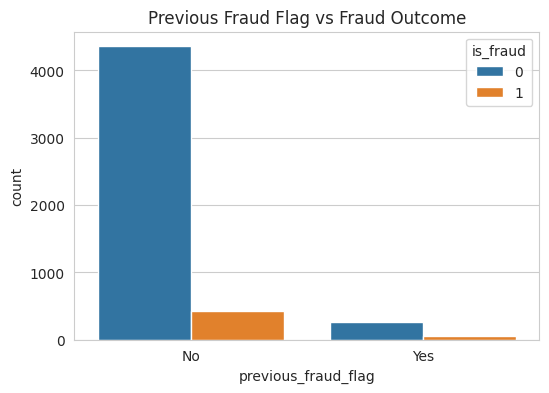

In [39]:
plt.figure(figsize=(6,4))
sns.countplot(x='previous_fraud_flag', hue='is_fraud', data=df)
plt.title('Previous Fraud Flag vs Fraud Outcome')
plt.show()
#  check whether customers with a prior confirmed fraud case are more likely to commit fraud again

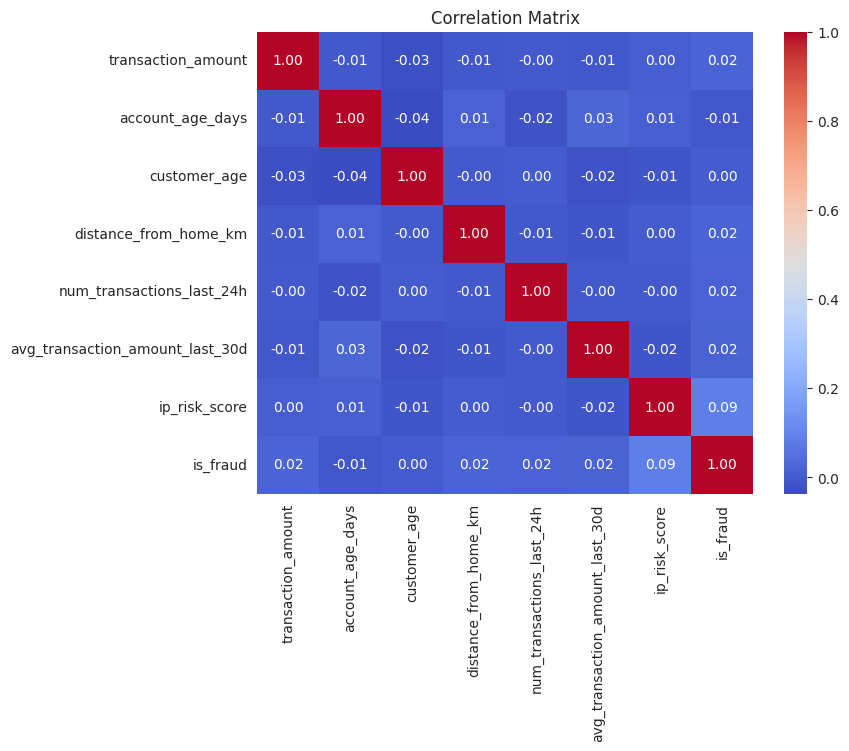

In [40]:
numeric_for_corr = ['transaction_amount', 'account_age_days', 'customer_age',
                     'distance_from_home_km', 'num_transactions_last_24h',
                     'avg_transaction_amount_last_30d', 'ip_risk_score', 'is_fraud']
plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_for_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# **Feature engineering**

In [41]:
df['is_cross_border'] = (df['customer_country'] != df['merchant_country']).astype(int)
# Checks if the customer’s home country is different from the country where the transaction happened.

# Bucket transaction hour into shift periods (night transactions are a common fraud signal)
def hour_bucket(h):
    if 0 <= h < 6:
        return 'Night'
    elif 6 <= h < 12:
        return 'Morning'
    elif 12 <= h < 18:
        return 'Afternoon'
    else:
        return 'Evening'

df['hour_bucket'] = df['transaction_hour'].apply(hour_bucket) # groups the hour of the transaction into a time-of-day label

# Ratio of this transaction to the customer's recent average — spending spikes are a fraud signal
df['amount_vs_avg_30d_ratio'] = df['transaction_amount'] / (df['avg_transaction_amount_last_30d'] + 1) # how unusual is this transaction size for this customer

df[['is_cross_border', 'hour_bucket', 'amount_vs_avg_30d_ratio']].head()

,is_cross_border,hour_bucket,amount_vs_avg_30d_ratio
0,1,Morning,0.197539
1,1,Evening,0.129699
2,0,Night,0.723392
3,1,Morning,5.910371
4,1,Night,0.757384


Select features and split data

In [42]:
target = 'is_fraud'

numeric_features = ['transaction_amount', 'account_age_days', 'customer_age',
                     'distance_from_home_km', 'transaction_hour',
                     'num_transactions_last_24h', 'avg_transaction_amount_last_30d',
                     'ip_risk_score', 'is_cross_border', 'amount_vs_avg_30d_ratio']

categorical_features = ['merchant_category', 'transaction_type', 'card_type',
                         'card_present', 'device_type', 'previous_fraud_flag',
                         'hour_bucket']

X = df[numeric_features + categorical_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y   # stratify preserves the fraud ratio in both splits
)

print("Train shape:", X_train.shape, " Fraud rate:", y_train.mean()) # Training set used to fit and tune the models
print("Test shape:", X_test.shape, " Fraud rate:", y_test.mean()) # Test set was used to evaluate their performance on unseen transactions

Train shape: (4080, 17)  Fraud rate: 0.09411764705882353
Test shape: (1020, 17)  Fraud rate: 0.09411764705882353


Preprocessing pipeline (encoding + scaling)

In [43]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # fill missing numeric values with the median
    ('scaler', StandardScaler())                    # standardise values to mean 0, std 1
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),  # fill missing categories with "Unknown"
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))        # convert categories to 0/1 columns
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),  # apply numeric steps to numeric columns
    ('cat', categorical_transformer, categorical_features)  # apply categorical steps to categorical columns
])
# Filling missing values, scaling numbers, and encoding categories — and made sure it only learned from the training set, so none of the test data leaked in.

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# **Model Training & Selection**

1. Naive baseline: Dummy Classifier (majority-class prediction)

In [44]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent', random_state=42)
dummy.fit(X_train_processed, y_train)

y_pred_dummy = dummy.predict(X_test_processed)
y_proba_dummy = dummy.predict_proba(X_test_processed)[:, 1]

print("Dummy Classifier — Naive Baseline")
print(classification_report(y_test, y_pred_dummy, digits=3))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_dummy))
print("PR-AUC:", average_precision_score(y_test, y_proba_dummy))

Dummy Classifier — Naive Baseline
              precision    recall  f1-score   support

           0      0.906     1.000     0.951       924
           1      0.000     0.000     0.000        96

    accuracy                          0.906      1020
   macro avg      0.453     0.500     0.475      1020
weighted avg      0.821     0.906     0.861      1020

ROC-AUC: 0.5
PR-AUC: 0.09411764705882353


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


2. Logistic Regression

In [45]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.pipeline import Pipeline as ImbPipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# SMOTE is placed INSIDE the pipeline so it's applied fresh within each CV fold, not once beforehand — resampling before the search would let
# synthetic points leak across the train/validation split of each fold.
lr_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
lr_param_grid = {'model__C': [0.01, 0.1, 1, 10]}

lr_search = GridSearchCV(lr_pipeline, lr_param_grid, scoring='average_precision', cv=cv, n_jobs=-1)
lr_search.fit(X_train_processed, y_train)
log_reg = lr_search.best_estimator_
print("Best C:", lr_search.best_params_, "| CV PR-AUC:", lr_search.best_score_)

y_pred_lr = log_reg.predict(X_test_processed)
y_proba_lr = log_reg.predict_proba(X_test_processed)[:, 1]

print("Logistic Regression")
print(classification_report(y_test, y_pred_lr, digits=3))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_lr))
print("PR-AUC:", average_precision_score(y_test, y_proba_lr))

Best C: {'model__C': 10} | CV PR-AUC: 0.32418956873853366
Logistic Regression
              precision    recall  f1-score   support

           0      0.961     0.765     0.852       924
           1      0.236     0.698     0.353        96

    accuracy                          0.759      1020
   macro avg      0.598     0.732     0.602      1020
weighted avg      0.892     0.759     0.805      1020

ROC-AUC: 0.80109126984127
PR-AUC: 0.39275896147745065


3. Random Forest

In [46]:
rf_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1))
])
rf_param_grid = {'model__n_estimators': [200, 300], 'model__max_depth': [8, 12]}

rf_search = GridSearchCV(rf_pipeline, rf_param_grid, scoring='average_precision', cv=3, n_jobs=-1)
rf_search.fit(X_train_processed, y_train)
rf = rf_search.best_estimator_
print("Best params:", rf_search.best_params_, "| CV PR-AUC:", rf_search.best_score_)

y_pred_rf = rf.predict(X_test_processed)
y_proba_rf = rf.predict_proba(X_test_processed)[:, 1]

print("Random Forest")
print(classification_report(y_test, y_pred_rf, digits=3))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_rf))
print("PR-AUC:", average_precision_score(y_test, y_proba_rf))

Best params: {'model__max_depth': 12, 'model__n_estimators': 300} | CV PR-AUC: 0.460435198469074
Random Forest
              precision    recall  f1-score   support

           0      0.951     0.938     0.944       924
           1      0.472     0.531     0.500        96

    accuracy                          0.900      1020
   macro avg      0.711     0.735     0.722      1020
weighted avg      0.906     0.900     0.903      1020

ROC-AUC: 0.8924062049062048
PR-AUC: 0.46583713176044056


4. XGBoost

In [47]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_param_grid = {'max_depth': [4, 6], 'learning_rate': [0.05, 0.1], 'n_estimators': [200, 300]}
xgb_search = GridSearchCV(
    XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=42),
    xgb_param_grid, scoring='average_precision', cv=3, n_jobs=-1
)
xgb_search.fit(X_train_processed, y_train)
xgb = xgb_search.best_estimator_
print("Best params:", xgb_search.best_params_, "| CV PR-AUC:", xgb_search.best_score_)

y_pred_xgb = xgb.predict(X_test_processed)
y_proba_xgb = xgb.predict_proba(X_test_processed)[:, 1]

print("XGBoost")
print(classification_report(y_test, y_pred_xgb, digits=3))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_xgb))
print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))

Best params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 200} | CV PR-AUC: 0.5217210322569491
XGBoost
              precision    recall  f1-score   support

           0      0.968     0.891     0.928       924
           1      0.406     0.719     0.519        96

    accuracy                          0.875      1020
   macro avg      0.687     0.805     0.723      1020
weighted avg      0.915     0.875     0.889      1020

ROC-AUC: 0.8915719696969697
PR-AUC: 0.5364227286854338


In [48]:
# Show predicted fraud probability for a few test transactions (XGBoost)
sample = X_test.head(5).copy()
sample['fraud_probability'] = y_proba_xgb[:5]
sample['predicted'] = y_pred_xgb[:5]
sample['actual'] = y_test.head(5).values
sample[['transaction_amount', 'fraud_probability', 'predicted', 'actual']]

,transaction_amount,fraud_probability,predicted,actual
212,204.67,0.324832,0,0
503,100.81,0.151599,0,0
4,177.97,0.501701,1,0
2727,93.28,0.466636,0,0
1696,689.02,0.933222,1,1


**Compare models: confusion matrices**

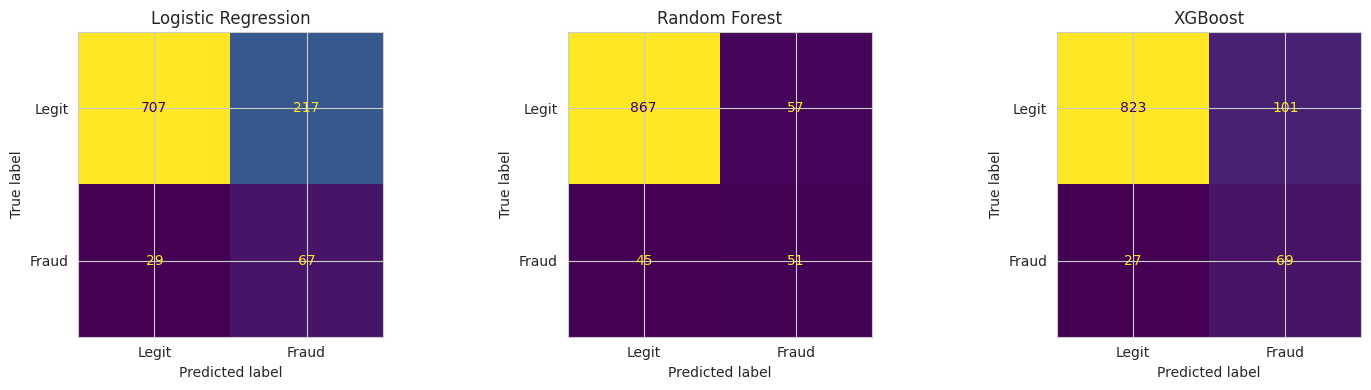

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, y_pred) in zip(axes, [('Logistic Regression', y_pred_lr),
                                       ('Random Forest', y_pred_rf),
                                       ('XGBoost', y_pred_xgb)]):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['Legit', 'Fraud']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Compare models: PR and ROC curves**

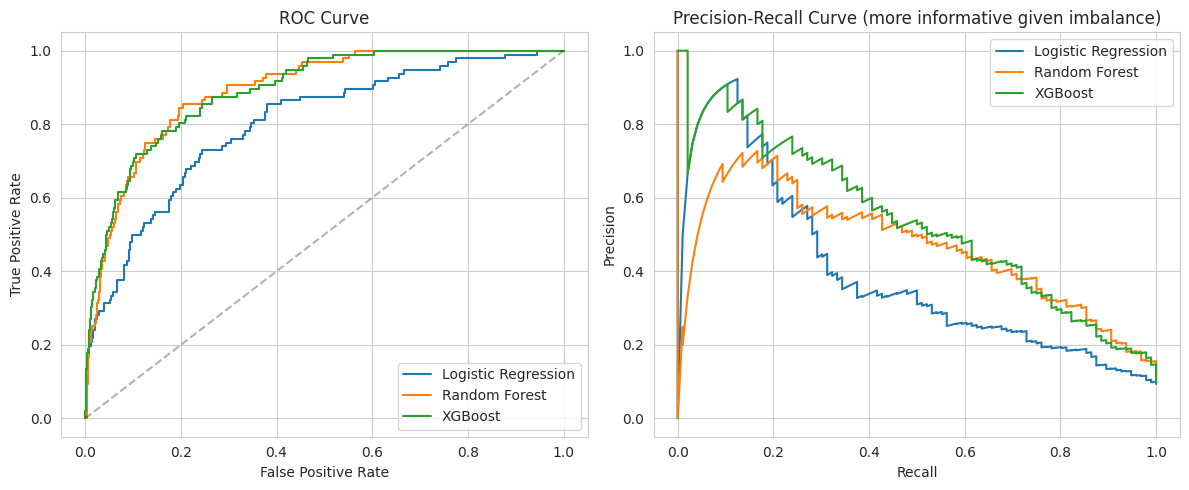

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, proba in [('Logistic Regression', y_proba_lr),
                     ('Random Forest', y_proba_rf),
                     ('XGBoost', y_proba_xgb)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=name)

    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=name)

axes[0].plot([0,1],[0,1],'k--', alpha=0.3)
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve'); axes[0].legend()

axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve (more informative given imbalance)'); axes[1].legend()

plt.tight_layout()
plt.show()

Precision-recall curve (more informative given our imbalance)

XGBoost’s curve is highest through most of the range, especially the middle, meaning it catches more fraud for a similar number of false alarms.
PR-AUC: XGBoost 0.536, Random Forest 0.466, Logistic Regression 0.393.

Threshold analysis

THRESHOLD ANALYSIS RESULTS


,Model,Threshold,Precision,Recall,F1
0,Logistic Regression,0.10,0.096,1.000,0.175
1,Logistic Regression,0.15,0.098,1.000,0.179
2,Logistic Regression,0.20,0.101,0.990,0.183
3,Logistic Regression,0.25,0.106,0.979,0.191
4,Logistic Regression,0.30,0.116,0.969,0.207
5,Logistic Regression,0.35,0.131,0.927,0.229
6,Logistic Regression,0.40,0.157,0.875,0.266
7,Logistic Regression,0.45,0.193,0.802,0.312
8,Logistic Regression,0.50,0.236,0.698,0.353
9,Logistic Regression,0.55,0.288,0.531,0.374


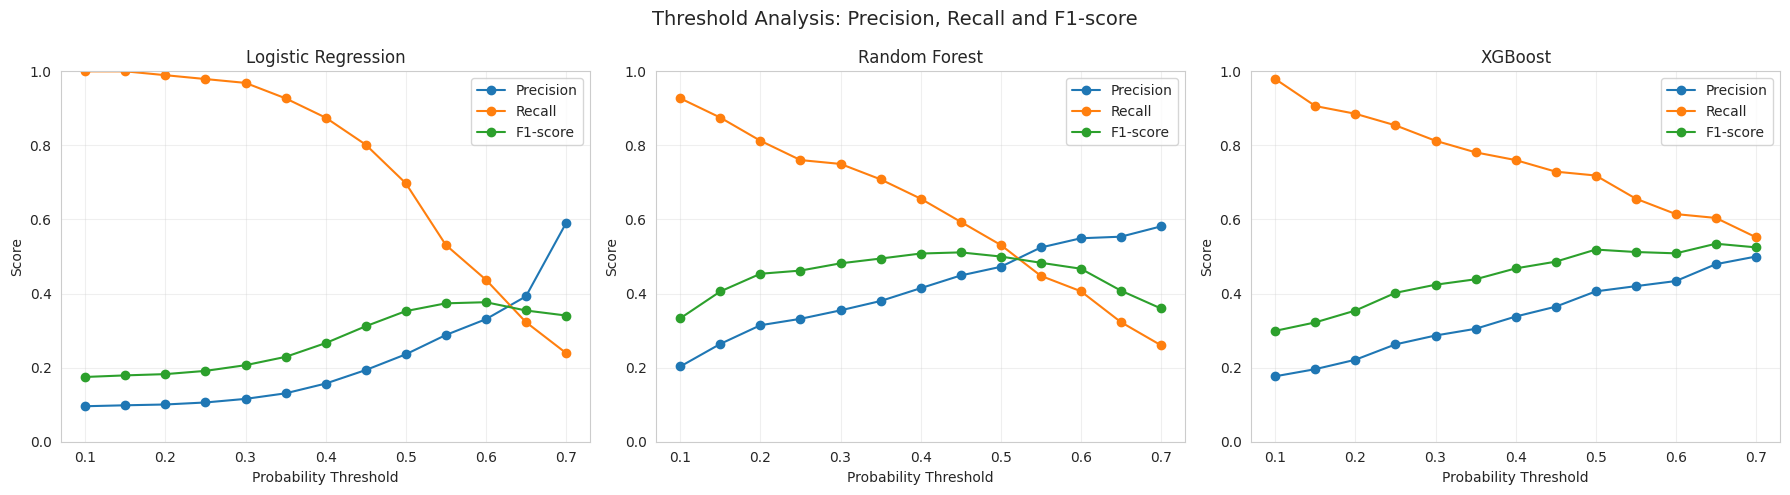

BEST F1-SCORE THRESHOLD FOR EACH MODEL


,Model,Threshold,Precision,Recall,F1
0,XGBoost,0.65,0.479,0.604,0.535
1,Random Forest,0.45,0.449,0.594,0.511
2,Logistic Regression,0.60,0.331,0.438,0.377


XGBoost Best F1 Threshold: 0.65

XGBoost Classification Report at Best F1 Threshold:
              precision    recall  f1-score   support

       Legit      0.958     0.932     0.945       924
       Fraud      0.479     0.604     0.535        96

    accuracy                          0.901      1020
   macro avg      0.719     0.768     0.740      1020
weighted avg      0.913     0.901     0.906      1020



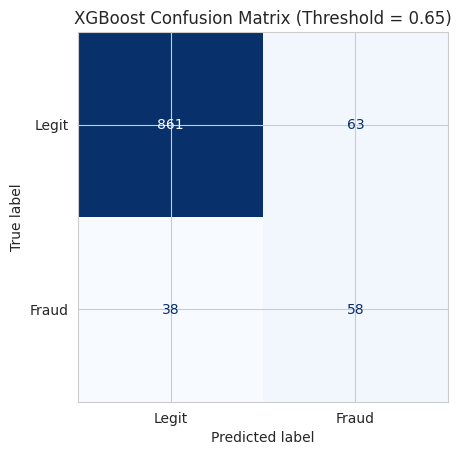

In [51]:
# Fraud detection is a decision problem. The default probability threshold of 0.50 is not necessarily optimal for an imbalanced dataset.
# This analysis evaluates different thresholds and shows the trade-off between Precision, Recall and F1-score.

from sklearn.metrics import precision_score, recall_score, f1_score

# Probability thresholds to evaluate
thresholds = np.arange(0.10, 0.71, 0.05)

# Predicted probabilities from the three trained models
models_proba = {
    'Logistic Regression': y_proba_lr,
    'Random Forest': y_proba_rf,
    'XGBoost': y_proba_xgb
}

threshold_results = []

# Calculate Precision, Recall and F1 at each threshold
for model_name, y_proba in models_proba.items():

    for threshold in thresholds:

        # Classify transaction as fraud when probability >= threshold
        y_pred_threshold = (y_proba >= threshold).astype(int)

        precision = precision_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        )

        recall = recall_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        )

        threshold_results.append({
            'Model': model_name,
            'Threshold': threshold,
            'Precision': precision,
            'Recall': recall,
            'F1': f1
        })

threshold_df = pd.DataFrame(threshold_results)

print("THRESHOLD ANALYSIS RESULTS")
display(threshold_df.round(3))


# PLOT PRECISION, RECALL AND F1 AGAINST THRESHOLD

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, model_name in zip(
    axes,
    ['Logistic Regression', 'Random Forest', 'XGBoost']
):

    model_data = threshold_df[
        threshold_df['Model'] == model_name
    ]

    ax.plot(
        model_data['Threshold'],
        model_data['Precision'],
        marker='o',
        label='Precision'
    )

    ax.plot(
        model_data['Threshold'],
        model_data['Recall'],
        marker='o',
        label='Recall'
    )

    ax.plot(
        model_data['Threshold'],
        model_data['F1'],
        marker='o',
        label='F1-score'
    )

    ax.set_title(model_name)
    ax.set_xlabel('Probability Threshold')
    ax.set_ylabel('Score')
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle(
    'Threshold Analysis: Precision, Recall and F1-score',
    fontsize=14
)

plt.tight_layout()
plt.show()


# FIND BEST F1 THRESHOLD FOR EACH MODEL

best_thresholds = (
    threshold_df
    .loc[
        threshold_df.groupby('Model')['F1'].idxmax()
    ]
    .sort_values('F1', ascending=False)
    .reset_index(drop=True)
)

print("BEST F1-SCORE THRESHOLD FOR EACH MODEL")
display(best_thresholds.round(3))


# XGBOOST AT ITS BEST F1 THRESHOLD

xgb_best_threshold = best_thresholds.loc[
    best_thresholds['Model'] == 'XGBoost',
    'Threshold'
].iloc[0]

y_pred_xgb_threshold = (
    y_proba_xgb >= xgb_best_threshold
).astype(int)

print(
    f"XGBoost Best F1 Threshold: "
    f"{xgb_best_threshold:.2f}"
)

print("\nXGBoost Classification Report at Best F1 Threshold:")

print(
    classification_report(
        y_test,
        y_pred_xgb_threshold,
        target_names=['Legit', 'Fraud'],
        digits=3,
        zero_division=0
    )
)


# XGBOOST CONFUSION MATRIX AT BEST F1 THRESHOLD

cm_xgb_threshold = confusion_matrix(
    y_test,
    y_pred_xgb_threshold
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb_threshold,
    display_labels=['Legit', 'Fraud']
)

disp.plot(
    cmap='Blues',
    colorbar=False
)

plt.title(
    f'XGBoost Confusion Matrix '
    f'(Threshold = {xgb_best_threshold:.2f})'
)

plt.show()


**Feature importance (interpretability for the discussion)**

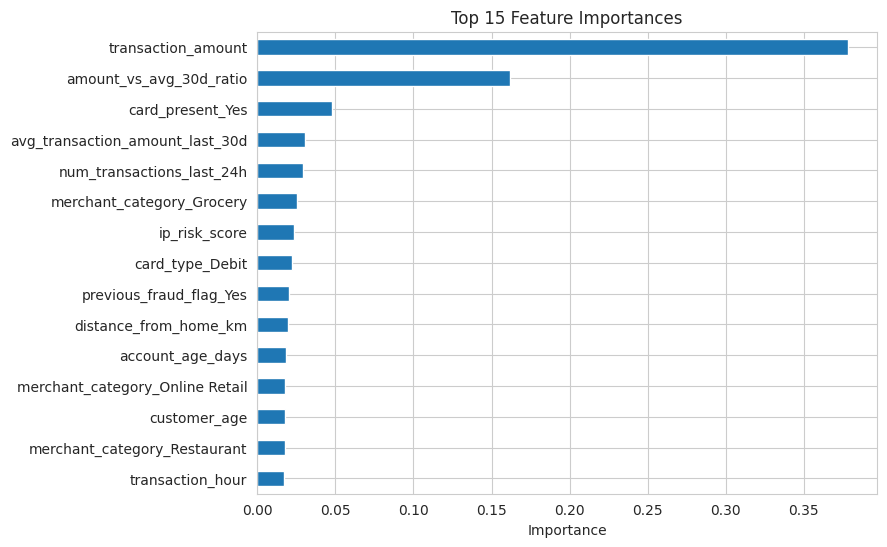

transaction_amount                 0.378042
amount_vs_avg_30d_ratio            0.162070
card_present_Yes                   0.047581
avg_transaction_amount_last_30d    0.030306
num_transactions_last_24h          0.029039
merchant_category_Grocery          0.025374
ip_risk_score                      0.023710
card_type_Debit                    0.022476
previous_fraud_flag_Yes            0.020055
distance_from_home_km              0.019725
account_age_days                   0.018282
merchant_category_Online Retail    0.017632
customer_age                       0.017620
merchant_category_Restaurant       0.017553
transaction_hour                   0.017338
dtype: float64


In [52]:
# Get feature names after preprocessing
feature_names = (
    numeric_features +
    list(
        preprocessor.named_transformers_['cat']
        .named_steps['onehot']
        .get_feature_names_out(categorical_features)
    )
)

# Get feature importances contributed most to the model’s predictions
importances = pd.Series(
    rf.named_steps['model'].feature_importances_,
    index=feature_names
).sort_values(ascending=False)

# Plot top 15 features
plt.figure(figsize=(8, 6))
importances.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Top 15 Feature Importances')
plt.xlabel('Importance')
plt.show()

# Display importance values
print(importances.head(15))

Summary results table

In [53]:
results = pd.DataFrame({
    'Model': ['Dummy (naive)', 'Logistic Regression', 'Random Forest', 'XGBoost'],
    'Precision (Fraud)': [None, None, None, None],
    'Recall (Fraud)': [None, None, None, None],
    'F1 (Fraud)': [None, None, None, None],
    'ROC-AUC': [roc_auc_score(y_test, y_proba_dummy), roc_auc_score(y_test, y_proba_lr),
                roc_auc_score(y_test, y_proba_rf), roc_auc_score(y_test, y_proba_xgb)],
    'PR-AUC': [average_precision_score(y_test, y_proba_dummy), average_precision_score(y_test, y_proba_lr),
               average_precision_score(y_test, y_proba_rf), average_precision_score(y_test, y_proba_xgb)]
})

from sklearn.metrics import precision_score, recall_score, f1_score
for i, y_pred in enumerate([y_pred_dummy, y_pred_lr, y_pred_rf, y_pred_xgb]):
    results.loc[i, 'Precision (Fraud)'] = precision_score(y_test, y_pred, zero_division=0)
    results.loc[i, 'Recall (Fraud)'] = recall_score(y_test, y_pred)
    results.loc[i, 'F1 (Fraud)'] = f1_score(y_test, y_pred)

results

,Model,Precision (Fraud),Recall (Fraud),F1 (Fraud),ROC-AUC,PR-AUC
0,Dummy (naive),0.0,0.0,0.0,0.500000,0.094118
1,Logistic Regression,0.235915,0.697917,0.352632,0.801091,0.392759
2,Random Forest,0.472222,0.53125,0.5,0.892406,0.465837
3,XGBoost,0.405882,0.71875,0.518797,0.891572,0.536423


The key point is that the model does not prove a transaction is fraudulent. It estimates risk and can help a financial institution decide which transactions may need further investigation.
